# Modellvergleich
Liest die Ergebnisse aus MLflow, rechnet nichts neu. Voraussetzung: MLflow-Server läuft (`make mlflow`) und `make train` wurde ausgeführt.

In [1]:
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from IPython.display import Image

from src.config import CHAMPION_ALIAS, EXPERIMENT_NAME, MODEL_NAME
from src.utils.mlflow_connection import connect_mlflow

client = connect_mlflow()
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME], order_by=["start_time DESC"])

# Letzter Trainingslauf und seine Kandidaten (Child-Runs)
training = runs[runs["tags.mlflow.runName"] == "training"].iloc[0]
candidates = runs[runs["tags.mlflow.parentRunId"] == training["run_id"]]
candidates.set_index("tags.mlflow.runName")[["metrics.cv_roc_auc", "metrics.val_roc_auc"]].round(3)

,metrics.cv_roc_auc,metrics.val_roc_auc
tags.mlflow.runName,,
gradient_boosting,0.668,0.665
random_forest,0.667,0.659
logistic_regression,0.680,0.667


In [2]:
# Hyperparameter, die die Grid Search je Modell gewählt hat
params = candidates.set_index("tags.mlflow.runName").filter(like="params.")
params.columns = params.columns.str.removeprefix("params.model__")
params.dropna(axis=1, how="all")

,max_depth,learning_rate,min_samples_leaf,C
tags.mlflow.runName,,,,
gradient_boosting,2,0.05,None,None
random_forest,6,None,20,None
logistic_regression,None,None,None,0.01


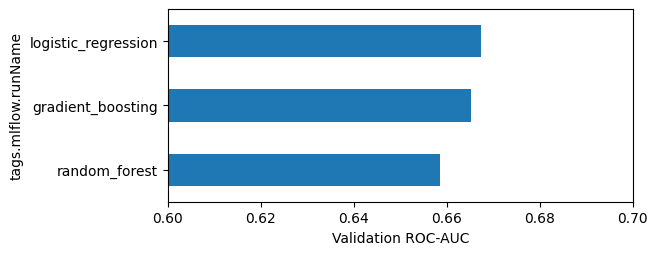

In [3]:
# Auswahl über den Validation-Split: Die einfache logistische Regression liegt vorn,
# die Baum-Ensembles bringen auf diesen 13 Merkmalen keinen Vorteil.
ax = candidates.set_index("tags.mlflow.runName")["metrics.val_roc_auc"].sort_values().plot.barh(figsize=(6, 2.5))
ax.set_xlim(0.6, 0.7)
ax.set_xlabel("Validation ROC-AUC")
plt.show()

## Freigegebenes Modell

In [4]:
champion = client.get_model_version_by_alias(MODEL_NAME, CHAMPION_ALIAS)
run = client.get_run(champion.run_id)
params = run.data.params
print(f"{MODEL_NAME} v{champion.version}: {params['model_type']}, Schwellenwert {params['threshold']}")
# Testmetriken, einmalig auf dem zurückgehaltenen Test-Split berechnet
pd.Series({k: v for k, v in run.data.metrics.items() if k.startswith("test_")}).round(3)

credit-risk-model v1: logistic_regression, Schwellenwert 0.5392


test_roc_auc      0.680
test_precision    0.263
test_recall       0.463
test_f1           0.335
dtype: float64

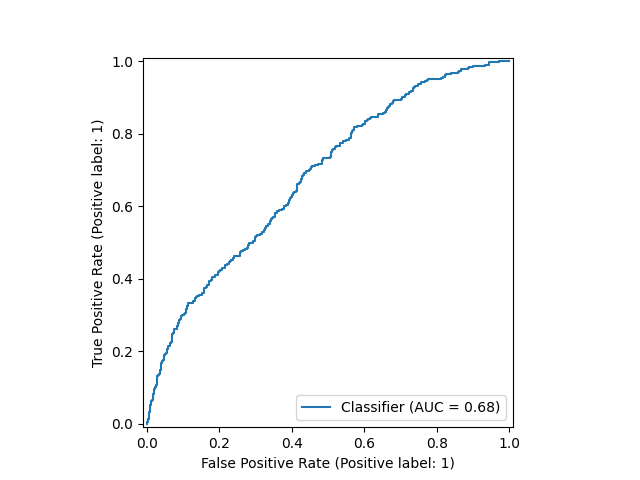

In [5]:
Image(mlflow.artifacts.download_artifacts(run_id=champion.run_id, artifact_path="roc_curve.png"))

In [6]:
# Registry-Verlauf: jede Version mit Freigabe-Entscheidung
versions = client.search_model_versions(f"name='{MODEL_NAME}'")
pd.DataFrame(
    [
        {
            "version": v.version,
            "promotion": v.tags.get("promotion"),
            "reason": v.tags.get("reason", ""),
            "aliases": ", ".join(v.aliases),
        }
        for v in versions
    ]
).sort_values("version")

,version,promotion,reason,aliases
0,1,accepted,,
